<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/10_shift_comparison_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/10_shift_comparison_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 6: format shifts vs mechanics shifts, on one footing

*AI-assisted: every code and markdown cell was generated with Claude (Opus 5.5) on 2026-11-09 and reviewed, run and edited by Andrew Reicin. None of this text is for the slides or report.*

Descriptive question: are differences in design between decades moving more with **play time, player count and minimum age** ("format") or with **the number and mix of mechanics**?

- **Option A:** how well each group of features tells old games (1970-1999) from new games (2010 on), by ROC AUC.
- **Option B:** how far each feature moved from the 1970s to the 2020s, in standard deviations.
- Both are run on all games and on non-wargames only (Task 5 showed many shifts come from wargames shrinking).
- Mechanics: number per game plus notebook 02's 12 most common. "Solo / Solitaire Game" is not among them; solo play is covered by minimum players.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Imports; reviewed and edited by Andrew Reicin.
# --- Andrew Reicin: Task 6, putting format shifts and mechanics shifts on one footing ---
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Every code and markdown cell in this notebook was generated with Claude and reviewed, run and edited by Andrew Reicin.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."
def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

GROUP_COLORS = {"Format": "tab:orange", "Mechanics": "tab:purple"}

## 1. Games and features

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Load the data and keep games with every format feature and at least one mechanic; reviewed and edited by Andrew Reicin.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")

format_raw = ["minplaytime", "maxplaytime", "minplayers", "maxplayers", "minage"]
dec = games[games["decade"] >= 1970].copy()
print("games 1970s to 2020s:", len(dec))
dec = dec.dropna(subset=format_raw + ["boardgamemechanic"]).copy()
dec["decade"] = dec["decade"].astype(int)
print("with all format features and at least one mechanic:", len(dec))
dec["decade"].value_counts().sort_index().to_frame("games")

games 1970s to 2020s: 20983
with all format features and at least one mechanic: 17842


,games
decade,
1970,678
1980,1145
1990,1654
2000,3697
2010,9122
2020,1546


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Build the format and mechanics features; reviewed and edited by Andrew Reicin.
# Format: play times and player counts on a log10 scale, as in notebooks 03 and 04; minimum age as is.
for col in ["minplaytime", "maxplaytime", "minplayers", "maxplayers"]:
    dec["log_" + col] = np.log10(dec[col])
format_features = ["log_minplaytime", "log_maxplaytime", "log_minplayers", "log_maxplayers", "minage"]

# Mechanics: number listed per game, plus 0/1 columns for notebook 02's 12 most common mechanics.
all_mech = games[(games["decade"] >= 1970) & games["boardgamemechanic"].notna()]["boardgamemechanic"].str.get_dummies(sep="|")
top12 = list(all_mech.mean().sort_values(ascending=False).head(12).index)
mech = dec["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=top12, fill_value=0)
dec = pd.concat([dec, mech], axis=1)
mechanics_features = ["n_mechanics"] + top12

print("format features:", format_features)
print("mechanics features:", mechanics_features)
print("'Solo / Solitaire Game' among the mechanics:", "Solo / Solitaire Game" in top12)

format features: ['log_minplaytime', 'log_maxplaytime', 'log_minplayers', 'log_maxplayers', 'minage']
mechanics features: ['n_mechanics', 'Dice Rolling', 'Hand Management', 'Set Collection', 'Variable Player Powers', 'Hexagon Grid', 'Simulation', 'Card Drafting', 'Tile Placement', 'Modular Board', 'Area Majority / Influence', 'Grid Movement', 'Cooperative Game']
'Solo / Solitaire Game' among the mechanics: False


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. The two sets of games: all games, and non-wargames; reviewed and edited by Andrew Reicin.
# Non-wargames: a category is listed and it does not include Wargame (same rule as Task 5).
is_nonwar = dec["boardgamecategory"].notna() & ~dec["boardgamecategory"].fillna("").str.contains("Wargame")
datasets = {"All games": dec, "Non-wargames": dec[is_nonwar]}
pd.DataFrame({name: d["decade"].value_counts().sort_index() for name, d in datasets.items()})

,All games,Non-wargames
decade,,
1970,678,294
1980,1145,640
1990,1654,1116
2000,3697,3015
2010,9122,8161
2020,1546,1370


## 2. Option B: how far each feature moved, in standard deviations

Each feature is standardized (StandardScaler, as in the PCA lab) so a shift of 1 means one standard deviation, whatever the feature's units. The shift is the 2020s average minus the 1970s average.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Shift of every feature, 1970s to 2020s; reviewed and edited by Andrew Reicin.
features = format_features + mechanics_features
group_of = {f: "Format" for f in format_features} | {f: "Mechanics" for f in mechanics_features}

def standardized(d):
    z = pd.DataFrame(StandardScaler().fit_transform(d[features]), columns=features, index=d.index)
    z["decade"] = d["decade"]
    return z

shift_tables = {}
for name, d in datasets.items():
    z = standardized(d)
    by_decade = z.groupby("decade")[features].mean()
    shift_tables[name] = by_decade.loc[2020] - by_decade.loc[1970]

shifts = pd.DataFrame(shift_tables)
shifts["group"] = shifts.index.map(group_of)
shifts.round(2).sort_values("All games")

,All games,Non-wargames,group
Hexagon Grid,-1.38,0.07,Mechanics
Simulation,-1.12,-0.26,Mechanics
log_minplaytime,-0.96,-0.30,Format
log_minplayers,-0.63,-0.63,Format
Dice Rolling,-0.53,0.08,Mechanics
Grid Movement,-0.50,0.06,Mechanics
log_maxplaytime,-0.46,0.32,Format
minage,0.16,0.75,Format
Tile Placement,0.25,0.08,Mechanics
Modular Board,0.27,0.30,Mechanics


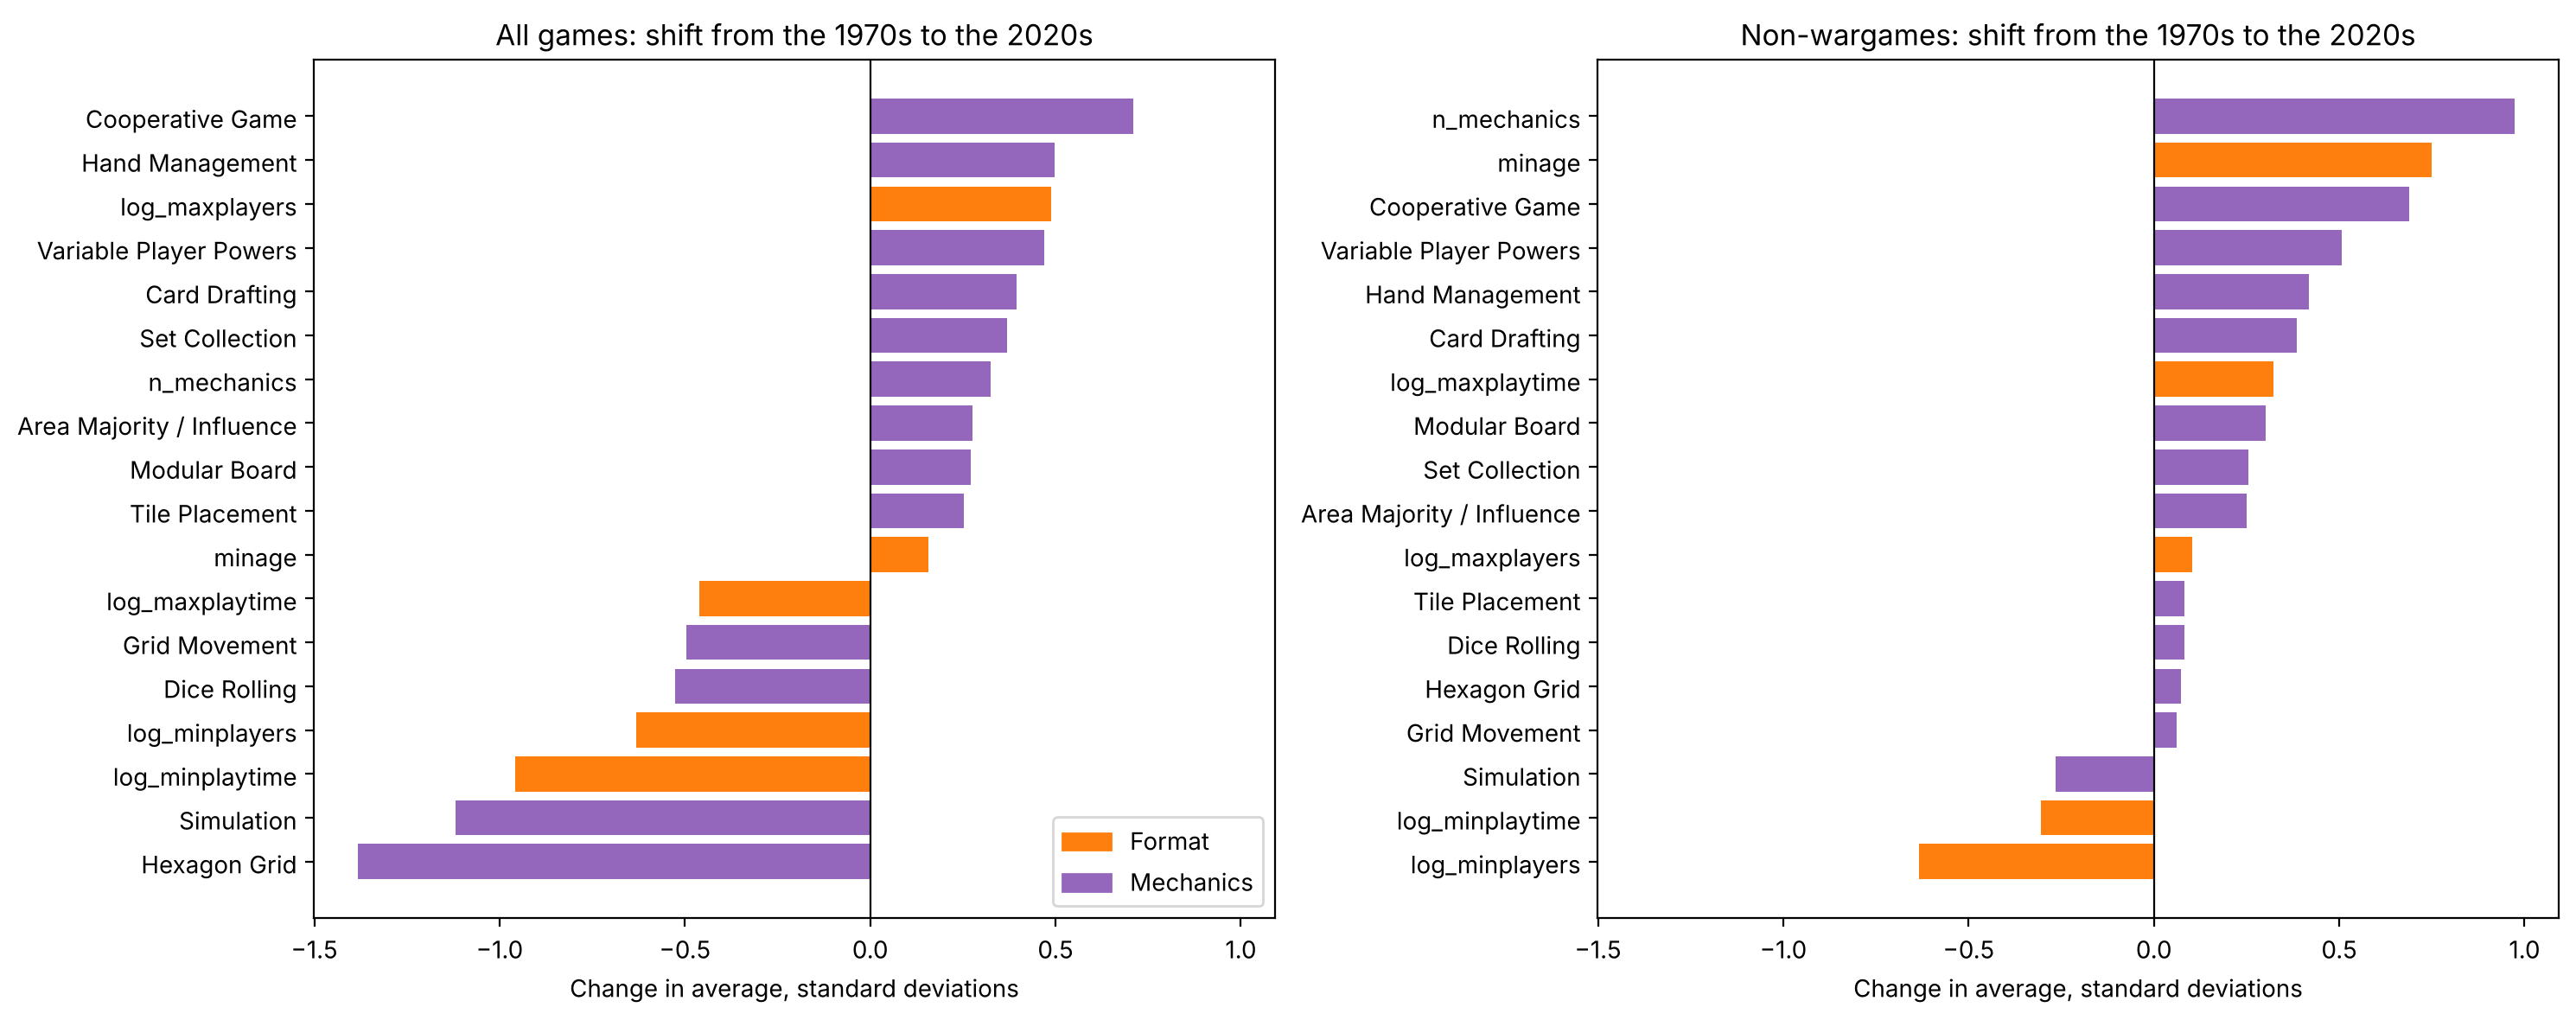

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Figure: every feature's shift, coloured by group; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, name in zip(axes, datasets):
    s = shifts[name].sort_values()
    ax.barh(s.index, s.values, color=[GROUP_COLORS[group_of[f]] for f in s.index])
    ax.axvline(x=0, color="black", linewidth=0.8)
    ax.set_title(f"{name}: shift from the 1970s to the 2020s")
    ax.set_xlabel("Change in average, standard deviations")
axes[0].legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items()], loc="lower right")
plt.tight_layout()
save("10_feature_shifts.png")
plt.show()

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Average size of the shift in each group; reviewed and edited by Andrew Reicin.
size = shifts[["All games", "Non-wargames"]].abs()
size["group"] = shifts["group"]
group_size = size.groupby("group").agg(["mean", "median", "max"]).round(2)
group_size

All games              Non-wargames             
               mean median   max         mean median   max
group                                                     
Format         0.54   0.49  0.96         0.42   0.32  0.75
Mechanics      0.55   0.47  1.38         0.33   0.26  0.97

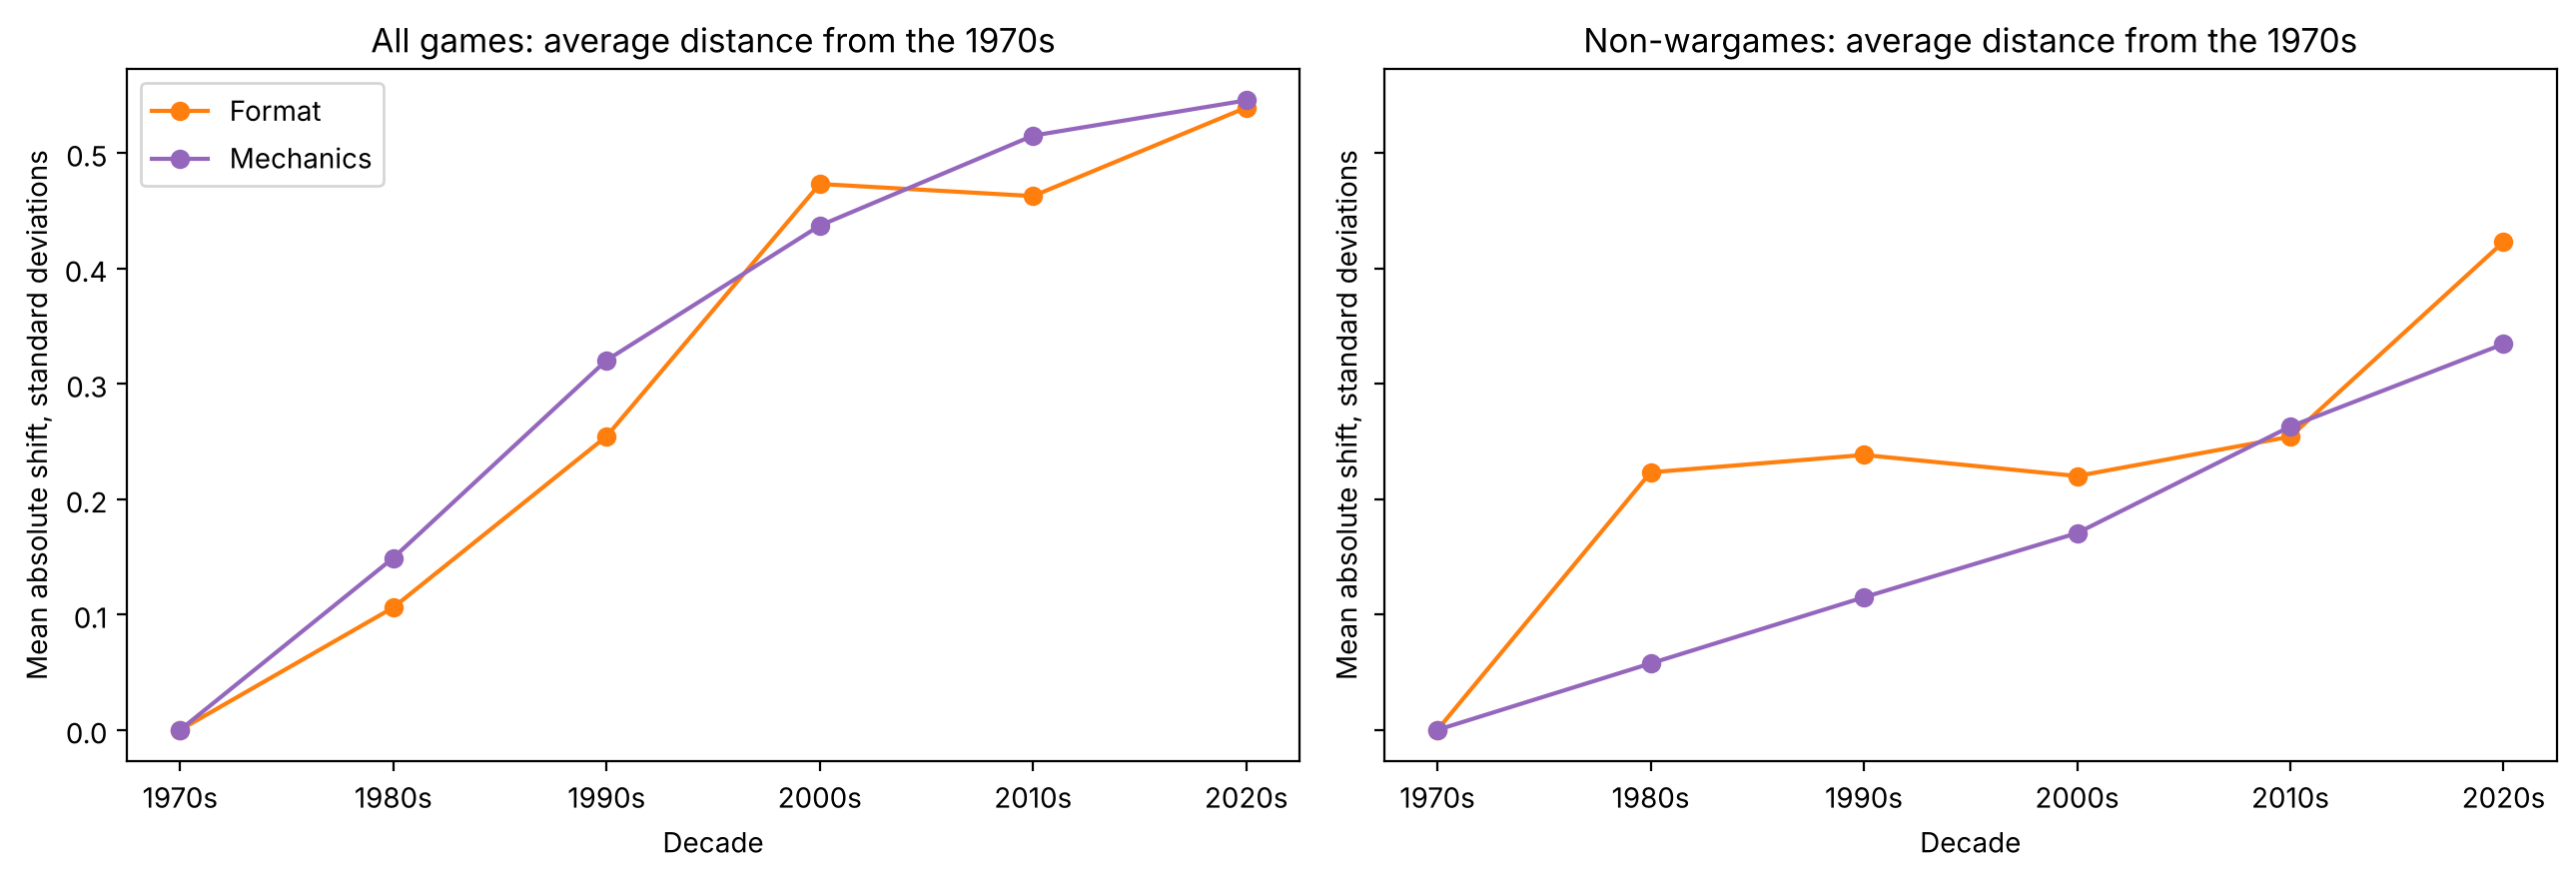

All games           Non-wargames          
          Format Mechanics       Format Mechanics
decade                                           
1970        0.00      0.00         0.00      0.00
1980        0.11      0.15         0.22      0.06
1990        0.25      0.32         0.24      0.11
2000        0.47      0.44         0.22      0.17
2010        0.46      0.51         0.25      0.26
2020        0.54      0.55         0.42      0.33

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Figure: average shift away from the 1970s, decade by decade; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
path_tables = {}
for ax, (name, d) in zip(axes, datasets.items()):
    by_decade = standardized(d).groupby("decade")[features].mean()
    away = (by_decade - by_decade.loc[1970]).abs()
    path = pd.DataFrame({g: away[[f for f in features if group_of[f] == g]].mean(axis=1) for g in GROUP_COLORS})
    path_tables[name] = path
    for g, c in GROUP_COLORS.items():
        ax.plot(path.index.astype(str) + "s", path[g], marker="o", color=c, label=g)
    ax.set_title(f"{name}: average distance from the 1970s")
    ax.set_xlabel("Decade")
    ax.set_ylabel("Mean absolute shift, standard deviations")
axes[0].legend()
plt.tight_layout()
save("10_shift_path.png")
plt.show()
pd.concat(path_tables, axis=1).round(2)

- **All games:** average shift 0.54 SD for format and 0.55 for mechanics, about a tie. The largest single shifts are mechanics (Hexagon Grid -1.38, Simulation -1.12), then minimum play time (-0.96).
- **Non-wargames:** format 0.42 vs mechanics 0.33. Hexagon Grid, Simulation and Dice Rolling barely move once wargames are removed; the largest shifts are mechanics per game (+0.97), minimum age (+0.75), Cooperative Game (+0.69) and minimum players (-0.63).
- The mechanics average depends on which 12 mechanics are included.

## 3. Option A: which features tell old games from new games

Old = published 1970-1999, new = 2010 on; the 2000s are left out as the transition. For each set of features a decision tree is tuned (max_depth and min_samples_leaf, 5-fold cross-validation on the training rows, `class_weight="balanced"` because new games outnumber old ones about three to one) and scored once on the test rows by ROC AUC (0.5 = coin flip, 1 = perfect). Split: 70/30, random state 1.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Tune and score a tree on format only, mechanics only, and both; reviewed and edited by Andrew Reicin.
# First attempt used max_depth up to 12 and min_samples_leaf down to 20; several trees chose those edge values,
# so the range was widened here (kept as a note, per ground rule 8).
param_grid = {"max_depth": [3, 5, 8, 10, 12, 15, 20, 25], "min_samples_leaf": [2, 5, 10, 20, 50, 100, 200]}
feature_sets = {"Format only": format_features, "Mechanics only": mechanics_features, "Both": format_features + mechanics_features}

results, best_trees = [], {}
for name, d in datasets.items():
    era = d[(d["decade"] <= 1990) | (d["decade"] >= 2010)]
    y = np.where(era["decade"] >= 2010, 1, 0)      # 1 = new (2010 on), 0 = old (1970-1999)
    for set_name, cols in feature_sets.items():
        X_train, X_test, y_train, y_test = train_test_split(era[cols], y, test_size=0.3, random_state=1)
        search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=0), param_grid,
                              cv=KFold(n_splits=5, shuffle=True, random_state=0), scoring="roc_auc").fit(X_train, y_train)
        test_auc = roc_auc_score(y_test, search.best_estimator_.predict_proba(X_test)[:, 1])
        results.append({"games": name, "features": set_name, "best settings": search.best_params_,
                        "CV AUC (training)": round(search.best_score_, 3), "test AUC": round(test_auc, 3),
                        "old games": int((y == 0).sum()), "new games": int((y == 1).sum())})
        best_trees[(name, set_name)] = search.best_estimator_
results = pd.DataFrame(results).set_index(["games", "features"])
results

best settings  \
games        features                                                    
All games    Format only     {'max_depth': 12, 'min_samples_leaf': 20}   
             Mechanics only  {'max_depth': 20, 'min_samples_leaf': 20}   
             Both            {'max_depth': 12, 'min_samples_leaf': 20}   
Non-wargames Format only     {'max_depth': 12, 'min_samples_leaf': 20}   
             Mechanics only  {'max_depth': 15, 'min_samples_leaf': 50}   
             Both            {'max_depth': 10, 'min_samples_leaf': 20}   

                             CV AUC (training)  test AUC  old games  new games  
games        features                                                           
All games    Format only                 0.874     0.887       3477      10668  
             Mechanics only              0.786     0.784       3477      10668  
             Both                        0.874     0.884       3477      10668  
Non-wargames Format only                 0.845     0.853       2050       9531  
             Mechanics only              0.723     0.723       2050       9531  
             Both                        0.854     0.844       2050       9531

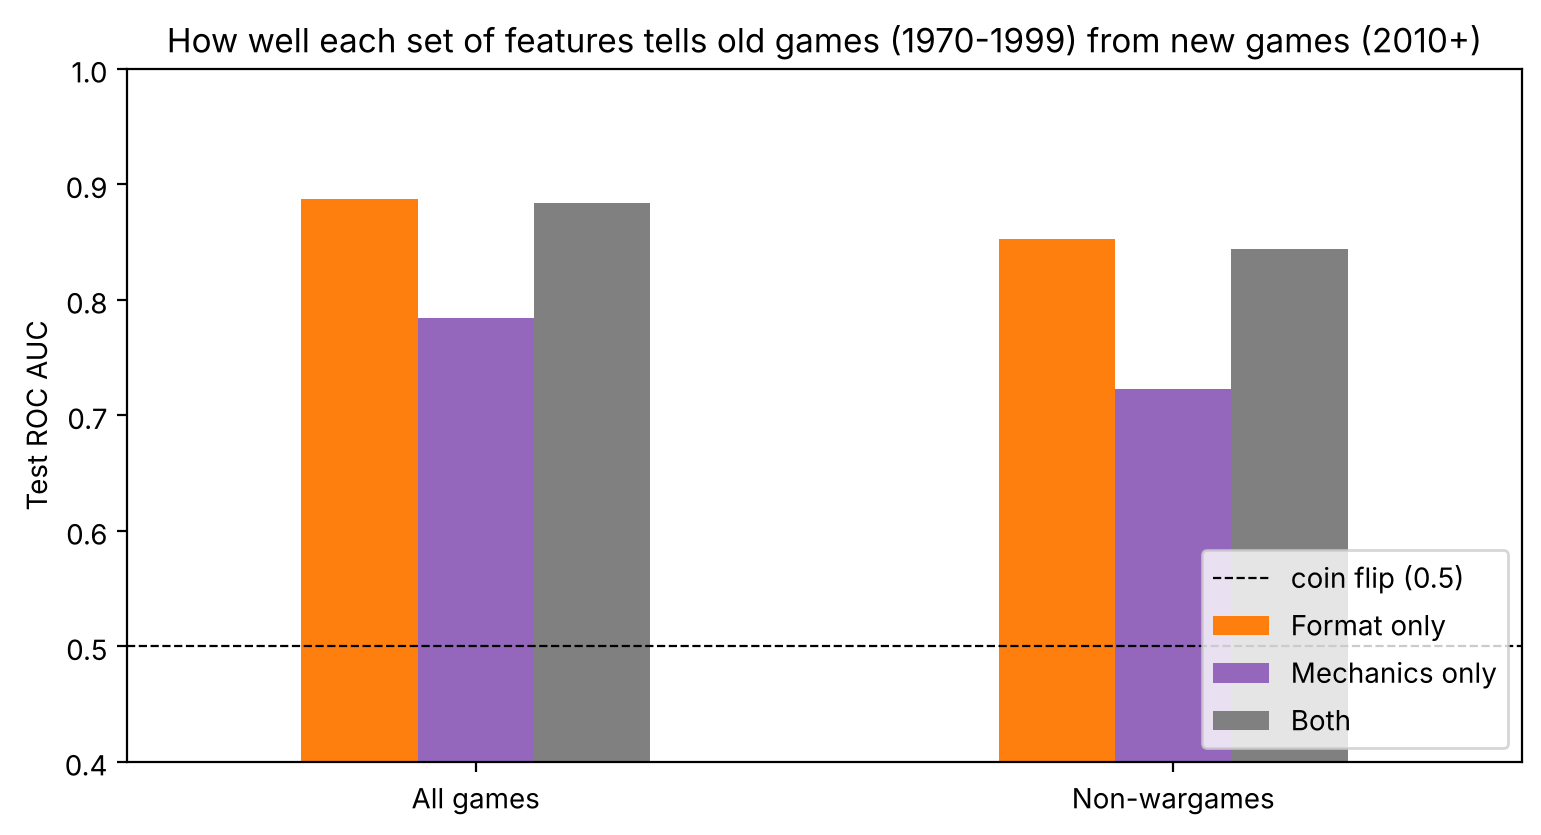

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Figure: test AUC by feature set; reviewed and edited by Andrew Reicin.
auc = results["test AUC"].unstack("features")[list(feature_sets)]
ax = auc.plot(kind="bar", figsize=(9, 4.5), rot=0, color=["tab:orange", "tab:purple", "0.5"])
ax.axhline(y=0.5, color="black", linestyle="--", linewidth=0.8, label="coin flip (0.5)")
ax.set_ylim(0.4, 1)
ax.set_title("How well each set of features tells old games (1970-1999) from new games (2010+)")
ax.set_xlabel("")
ax.set_ylabel("Test ROC AUC")
ax.legend(loc="lower right")
save("10_era_auc.png")
plt.show()

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Within the tree that uses both sets: how much of its splitting comes from each group; reviewed and edited by Andrew Reicin.
imp_tables = {}
for name in datasets:
    tree = best_trees[(name, "Both")]
    imp = pd.Series(tree.feature_importances_, index=feature_sets["Both"])
    imp_tables[name] = imp
importances = pd.DataFrame(imp_tables)
importances["group"] = importances.index.map(group_of)
print("Share of feature importance by group:")
print(importances.groupby("group")[list(datasets)].sum().round(3), "\n")
importances.sort_values("All games", ascending=False).round(3)

Share of feature importance by group:
           All games  Non-wargames
group                             
Format         0.851         0.797
Mechanics      0.149         0.203 



,All games,Non-wargames,group
log_minplaytime,0.421,0.293,Format
log_maxplaytime,0.199,0.233,Format
minage,0.179,0.202,Format
n_mechanics,0.047,0.118,Mechanics
log_maxplayers,0.037,0.057,Format
Hand Management,0.021,0.019,Mechanics
Hexagon Grid,0.021,0.000,Mechanics
Area Majority / Influence,0.016,0.016,Mechanics
log_minplayers,0.015,0.012,Format
Cooperative Game,0.015,0.022,Mechanics


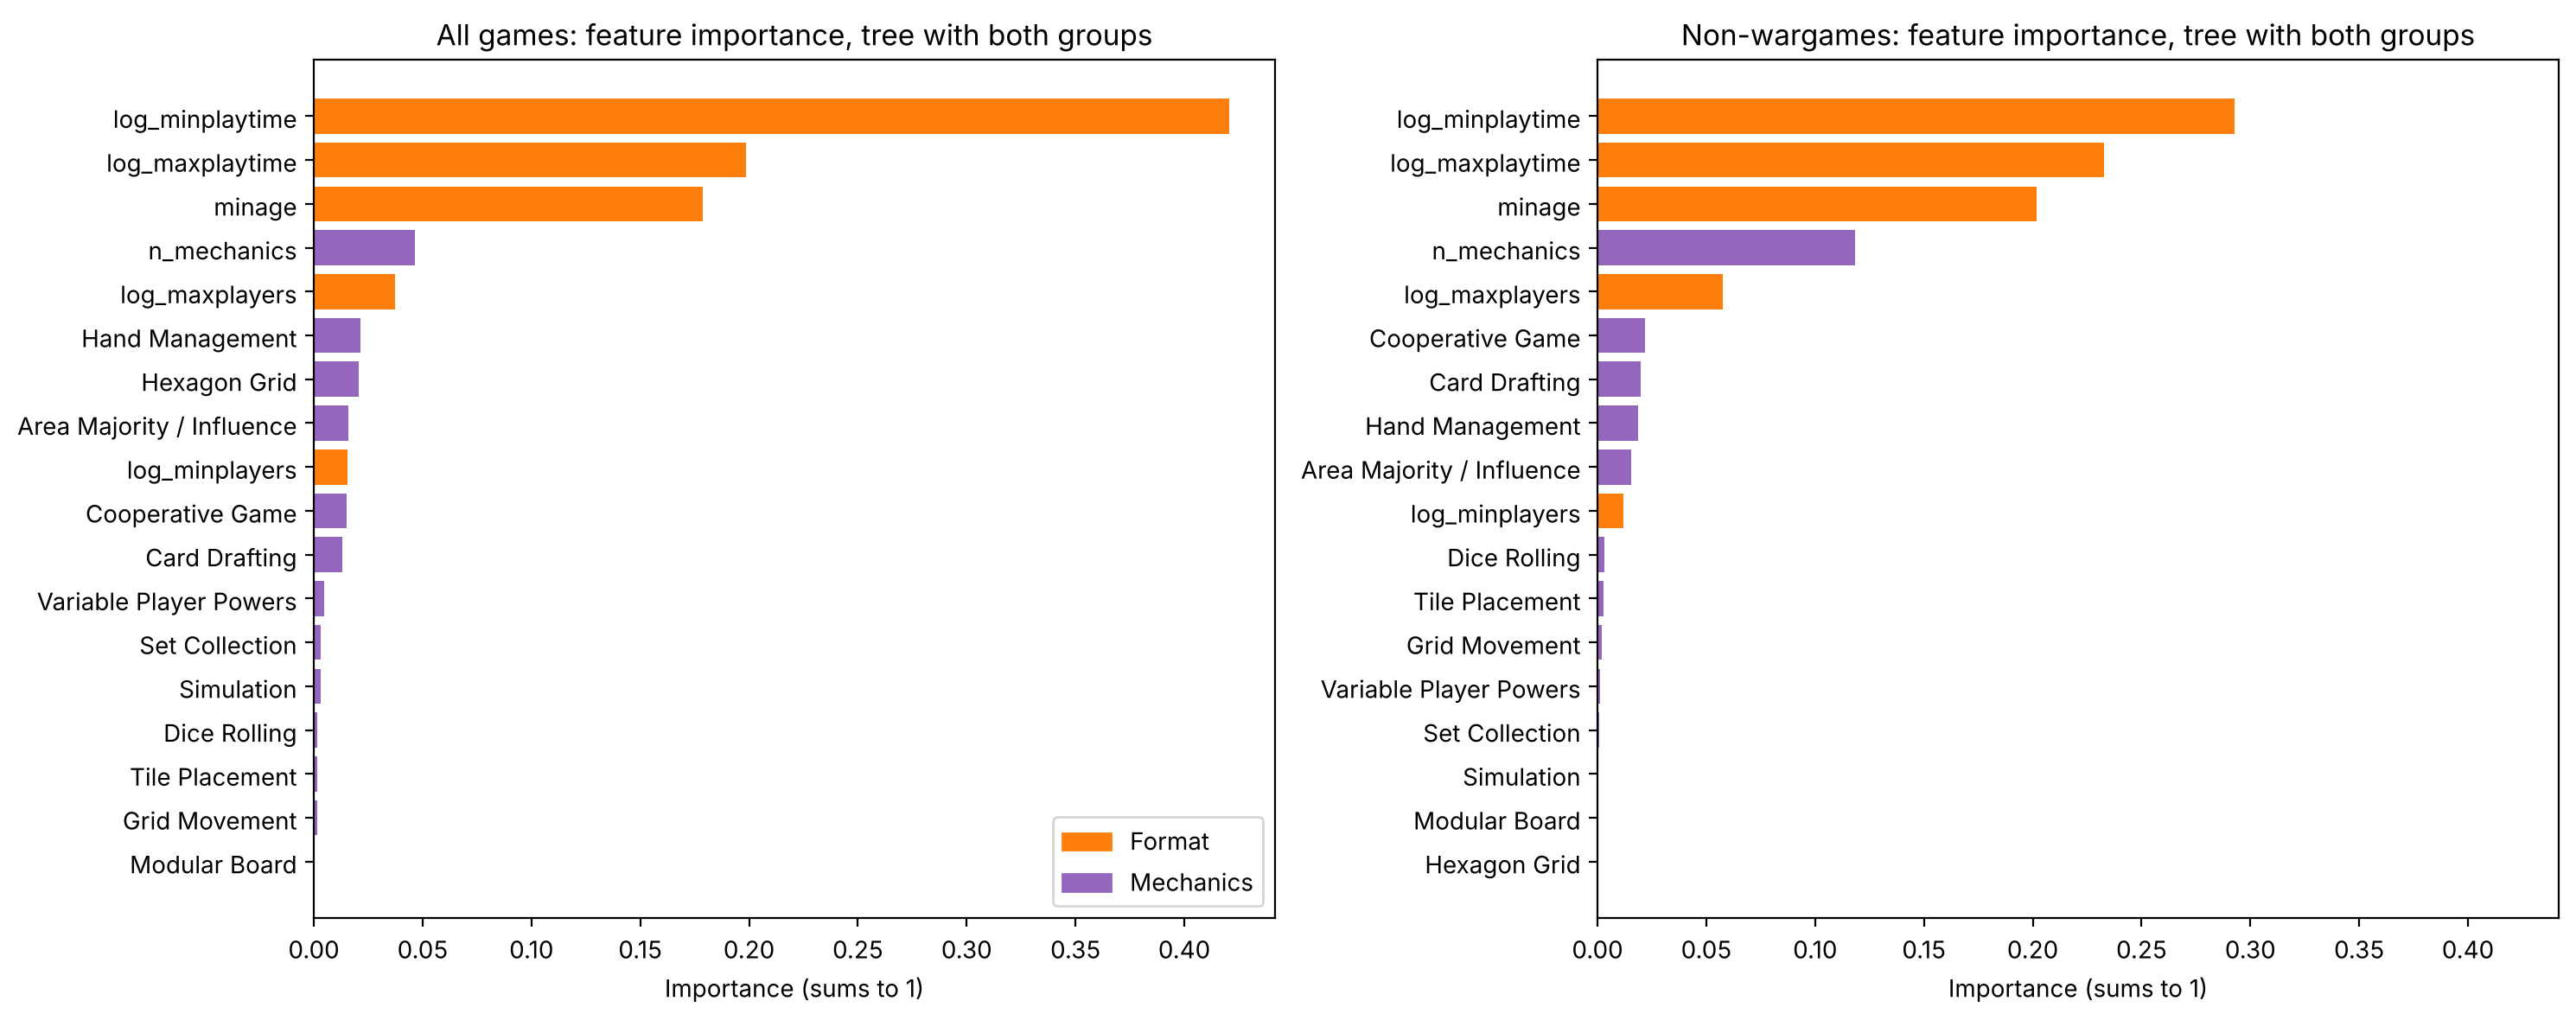

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Figure: feature importance in the combined tree; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, name in zip(axes, datasets):
    s = importances[name].sort_values()
    ax.barh(s.index, s.values, color=[GROUP_COLORS[group_of[f]] for f in s.index])
    ax.set_title(f"{name}: feature importance, tree with both groups")
    ax.set_xlabel("Importance (sums to 1)")
axes[0].legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items()], loc="lower right")
plt.tight_layout()
save("10_importance.png")
plt.show()

- **Format alone** tells old from new games best: test AUC 0.89 (all games) and 0.85 (non-wargames).
- **Mechanics alone:** 0.78 and 0.72. Adding mechanics to format does not improve the score (0.88 and 0.84).
- In the tree that uses both, format features carry 85% (all games) and 80% (non-wargames) of the importance, mostly play time and minimum age; the number of mechanics is the only mechanics feature with much weight. Tree importance tends to favour features with many values over 0/1 features, so these shares lean toward format; the AUC comparison does not have that bias.

## 4. Everything on one page

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Summary of both options, for all games and non-wargames; reviewed and edited by Andrew Reicin.
summary = pd.DataFrame({
    "B: mean shift, format (SD)": group_size.loc["Format"].xs("mean", level=1),
    "B: mean shift, mechanics (SD)": group_size.loc["Mechanics"].xs("mean", level=1),
    "A: test AUC, format only": results["test AUC"].xs("Format only", level="features"),
    "A: test AUC, mechanics only": results["test AUC"].xs("Mechanics only", level="features"),
    "A: test AUC, both": results["test AUC"].xs("Both", level="features"),
    "A: importance share, format": importances.groupby("group")[list(datasets)].sum().loc["Format"],
    "A: importance share, mechanics": importances.groupby("group")[list(datasets)].sum().loc["Mechanics"],
}).round(3)
summary.T

,All games,Non-wargames
"B: mean shift, format (SD)",0.540,0.420
"B: mean shift, mechanics (SD)",0.550,0.330
"A: test AUC, format only",0.887,0.853
"A: test AUC, mechanics only",0.784,0.723
"A: test AUC, both",0.884,0.844
"A: importance share, format",0.851,0.797
"A: importance share, mechanics",0.149,0.203


**Verdict (decided by Andrew Reicin): format, hedged.** Format separates the eras more clearly than mechanics in every run, and once wargames are removed it also moved further. Mechanics' large shifts across all games come mostly from the decline of wargames. The result depends on some choices: the 12 mechanics included, comparing 1970-1999 with 2010 on (skipping the 2000s), and tree importance favouring features with many values.